In [ ]:
import pandas as pd, numpy as np

In [1]:
df = pd.read_csv('/content/drive/MyDrive/INM/ML_Feb26/L42_Social_Network_Ads_1.csv')
## Dataset file provided in zip file with notebook

data = df.copy()

NameError: name 'pd' is not defined

In [ ]:
data

,User ID,Date,Country,Gender,Age,EstimatedSalary,Purchased
0,15624510,01-03-2012,France,Male,19,19000.0,0
1,15810944,01-04-2012,Italy,Male,35,20000.0,0
2,15668575,01-05-2012,France,Female,26,43000.0,0
3,15603246,01-06-2012,Germany,Female,27,57000.0,0
4,15804002,01-09-2012,France,Male,19,76000.0,0
...,...,...,...,...,...,...,...
398,15691863,08-05-2013,France,Female,46,41000.0,1
399,15706071,08-06-2013,Italy,Male,51,23000.0,1
400,15654296,08-07-2013,Italy,Female,50,20000.0,1
401,15755018,08-08-2013,Germany,Male,36,33000.0,0


In [ ]:
data['Purchased'].value_counts()/len(data)

,count
Purchased,
0,0.640199
1,0.359801


In [ ]:
data.isna().sum()

,0
User ID,0
Date,0
Country,0
Gender,0
Age,0
EstimatedSalary,2
Purchased,0


In [ ]:
data.dropna(subset=['EstimatedSalary'],inplace=True)
data.isna().sum()

,0
User ID,0
Date,0
Country,0
Gender,0
Age,0
EstimatedSalary,0
Purchased,0


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

def cont_analysis(data,col):
  series = data[col]
  print(series.agg(['min','max','mean','median','var','std','skew','kurt']).round(2))

  sns.histplot(series)
  plt.show()

  sns.kdeplot(series)
  plt.show()

  sns.boxplot(series)
  plt.show()



def cat_disc_analysis(data,col):
  print("Value Counts for",col)
  val_cnt = data[col].value_counts()
  print(val_cnt)
  print("Count of null values = ",data[col].isna().sum())

  sns.countplot(x=col,data=data)
  plt.show()

  plt.pie(val_cnt,labels=val_cnt.index,autopct='%1.1f%%')
  plt.show()

In [ ]:
data.columns

Index(['User ID', 'Date', 'Country', 'Gender', 'Age', 'EstimatedSalary',
       'Purchased'],
      dtype='object')

min        18.00
max        60.00
mean       37.76
median     37.00
var       109.33
std        10.46
skew        0.22
kurt       -0.62
Name: Age, dtype: float64


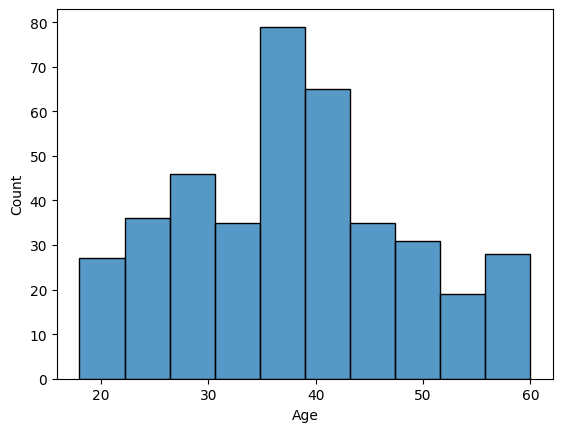

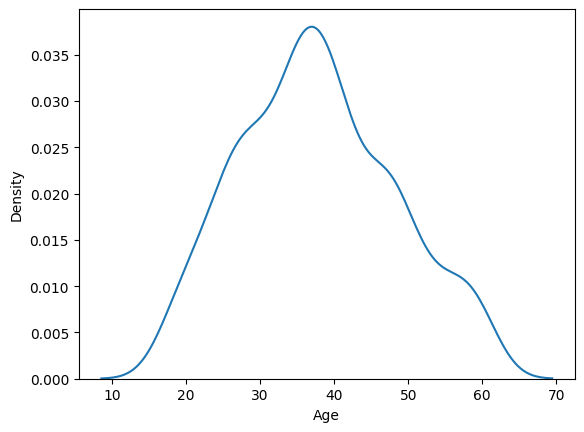

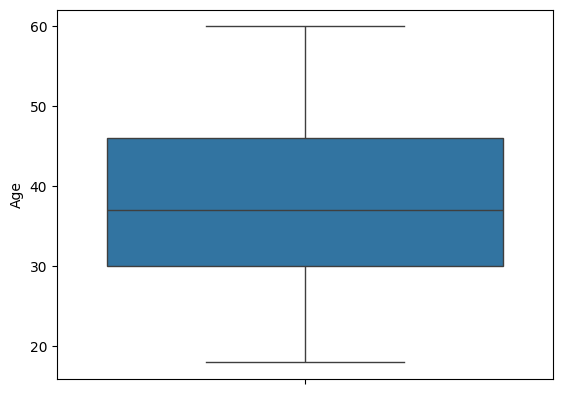

In [ ]:
cont_analysis(data,'Age')

min       1.500000e+04
max       5.000000e+06
mean      8.236658e+04
median    7.000000e+04
var       6.183755e+10
std       2.486716e+05
skew      1.943000e+01
kurt      3.851100e+02
Name: EstimatedSalary, dtype: float64


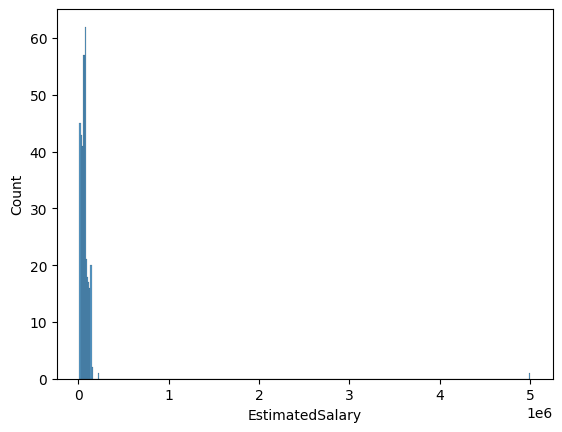

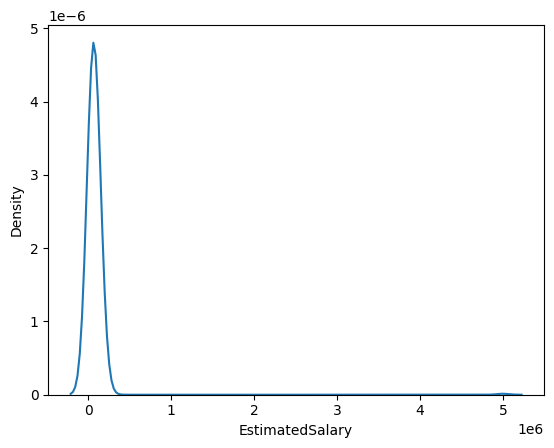

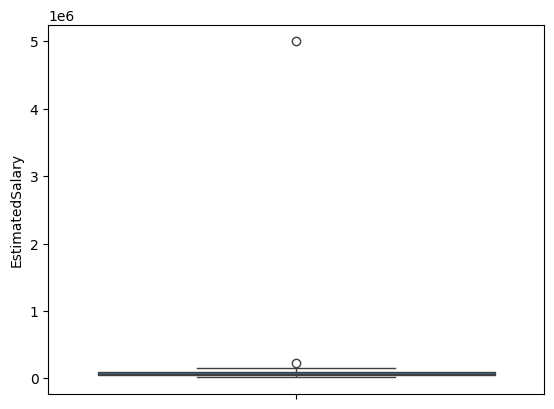

In [ ]:
cont_analysis(data,'EstimatedSalary')

In [ ]:
# Detect and handle outliers in EstimatedSalary

col = 'EstimatedSalary'
q1=data[col].quantile(0.25)
q3=data[col].quantile(0.75)
iqr=q3-q1

lower_limit = q1-1.5*iqr
upper_limit = q3+1.5*iqr

In [ ]:
outliers = data[(data['EstimatedSalary']<lower_limit) | (data['EstimatedSalary']>upper_limit)]
outliers

,User ID,Date,Country,Gender,Age,EstimatedSalary,Purchased
161,15734234,8/22/2012,France,Male,36,5000000.0,1
281,15613334,2/15/2013,Italy,Female,54,233000.0,1


In [ ]:
data.drop(outliers.index,axis=0,inplace=True)

min       1.500000e+04
max       1.500000e+05
mean      6.966416e+04
median    7.000000e+04
var       1.167917e+09
std       3.417480e+04
skew      5.000000e-01
kurt     -4.200000e-01
Name: EstimatedSalary, dtype: float64


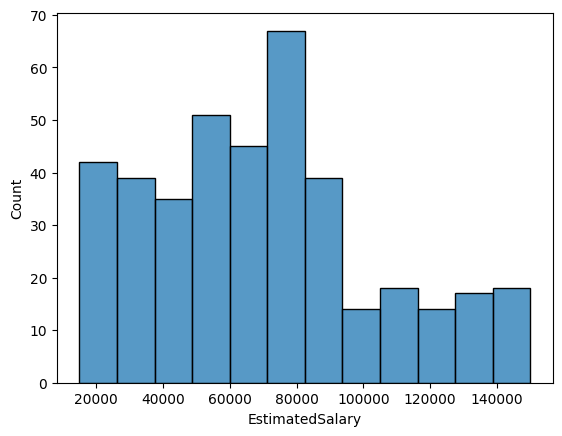

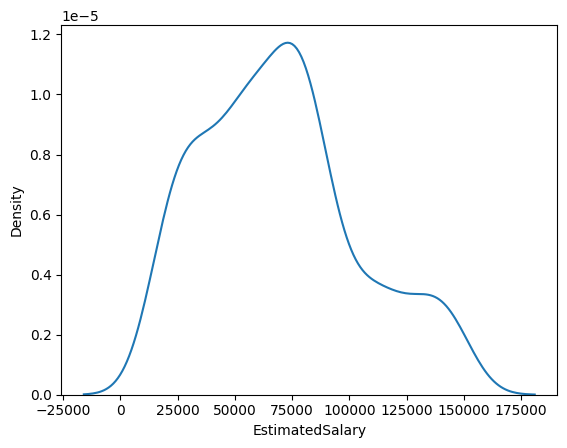

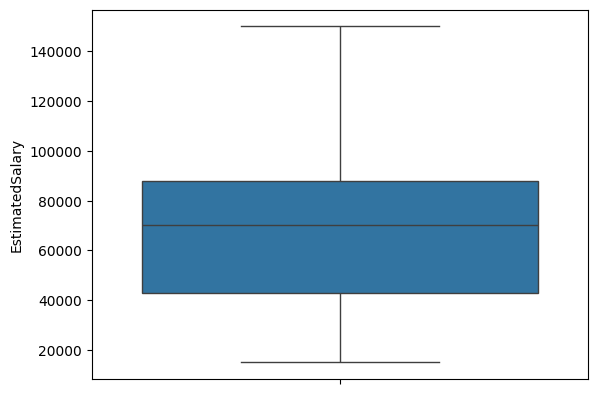

In [ ]:
cont_analysis(data,'EstimatedSalary')

Value Counts for Country
Country
Italy        139
Germany      132
France       124
]Italy&        2
]Germany&      1
Germany&       1
Name: count, dtype: int64
Count of null values =  0


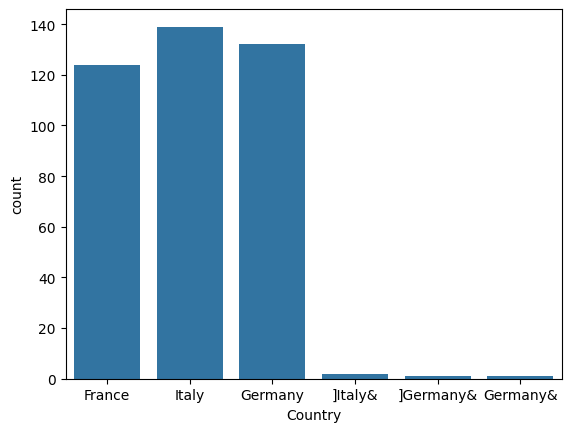

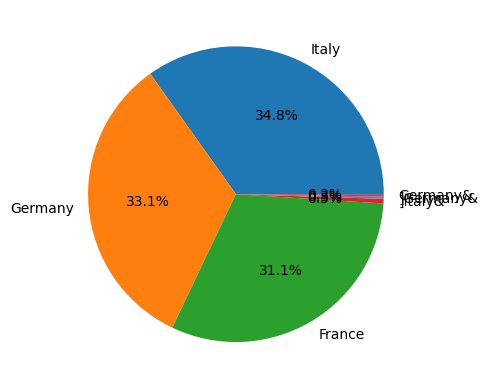

In [ ]:
cat_disc_analysis(data,'Country')

Value Counts for Country
Country
Italy      141
Germany    134
France     124
Name: count, dtype: int64
Count of null values =  0


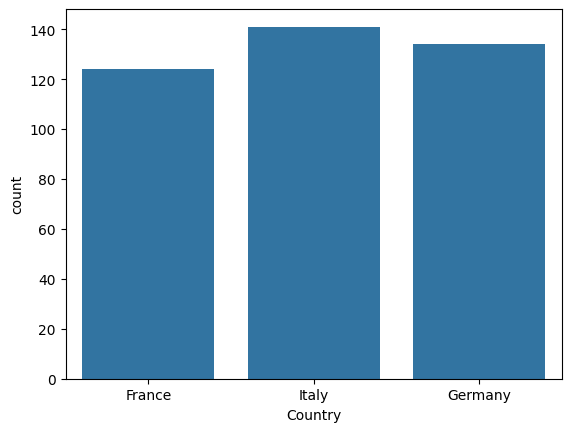

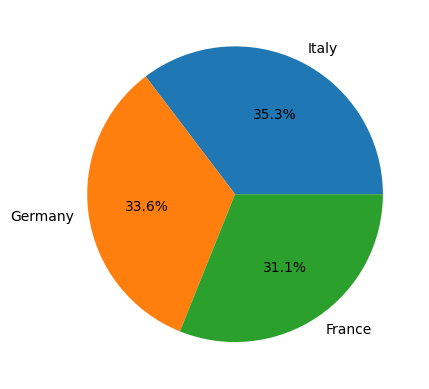

In [ ]:
data['Country']=data['Country'].apply(lambda x:x.replace(']','').replace('&',''))
cat_disc_analysis(data,'Country')

Value Counts for Gender
Gender
Female    202
Male      197
Name: count, dtype: int64
Count of null values =  0


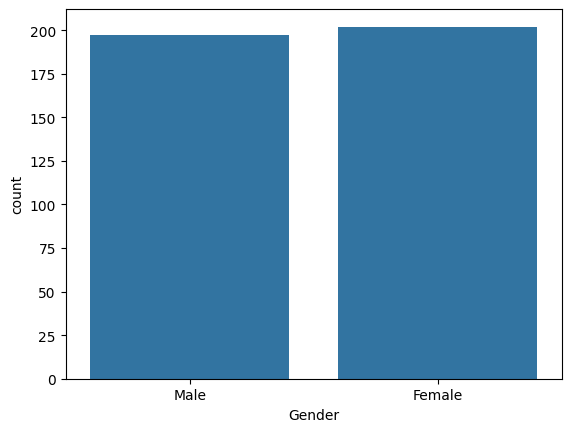

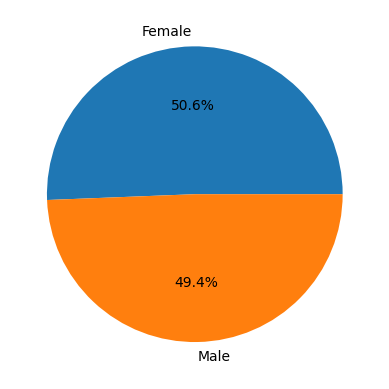

In [ ]:
cat_disc_analysis(data,'Gender')

In [ ]:
data.drop(['User ID','Date'],axis=1,inplace=True)
data

,Country,Gender,Age,EstimatedSalary,Purchased
0,France,Male,19,19000.0,0
1,Italy,Male,35,20000.0,0
2,France,Female,26,43000.0,0
3,Germany,Female,27,57000.0,0
4,France,Male,19,76000.0,0
...,...,...,...,...,...
398,France,Female,46,41000.0,1
399,Italy,Male,51,23000.0,1
400,Italy,Female,50,20000.0,1
401,Germany,Male,36,33000.0,0


In [ ]:
from sklearn.preprocessing import OneHotEncoder

In [ ]:
ohe1 = OneHotEncoder(sparse_output=False)
country_encoded = ohe1.fit_transform(data[['Country']])
country_encoded = pd.DataFrame(country_encoded,columns = ohe1.get_feature_names_out())
country_encoded

,Country_France,Country_Germany,Country_Italy
0,1.0,0.0,0.0
1,0.0,0.0,1.0
2,1.0,0.0,0.0
3,0.0,1.0,0.0
4,1.0,0.0,0.0
...,...,...,...
394,1.0,0.0,0.0
395,0.0,0.0,1.0
396,0.0,0.0,1.0
397,0.0,1.0,0.0


In [ ]:
ohe1 = OneHotEncoder(sparse_output=False)
gender_encoded = ohe1.fit_transform(data[['Gender']])
gender_encoded = pd.DataFrame(gender_encoded,columns = ohe1.get_feature_names_out())
gender_encoded

,Gender_Female,Gender_Male
0,0.0,1.0
1,0.0,1.0
2,1.0,0.0
3,1.0,0.0
4,0.0,1.0
...,...,...
394,1.0,0.0
395,0.0,1.0
396,1.0,0.0
397,0.0,1.0


In [ ]:
data = pd.concat([data.reset_index(drop=True),country_encoded,gender_encoded],axis=1)

In [ ]:
data

,Country,Gender,Age,EstimatedSalary,Purchased,Country_France,Country_Germany,Country_Italy,Gender_Female,Gender_Male
0,France,Male,19,19000.0,0,1.0,0.0,0.0,0.0,1.0
1,Italy,Male,35,20000.0,0,0.0,0.0,1.0,0.0,1.0
2,France,Female,26,43000.0,0,1.0,0.0,0.0,1.0,0.0
3,Germany,Female,27,57000.0,0,0.0,1.0,0.0,1.0,0.0
4,France,Male,19,76000.0,0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
394,France,Female,46,41000.0,1,1.0,0.0,0.0,1.0,0.0
395,Italy,Male,51,23000.0,1,0.0,0.0,1.0,0.0,1.0
396,Italy,Female,50,20000.0,1,0.0,0.0,1.0,1.0,0.0
397,Germany,Male,36,33000.0,0,0.0,1.0,0.0,0.0,1.0


## SMOTE - Class Balancing

<Axes: xlabel='Purchased', ylabel='count'>

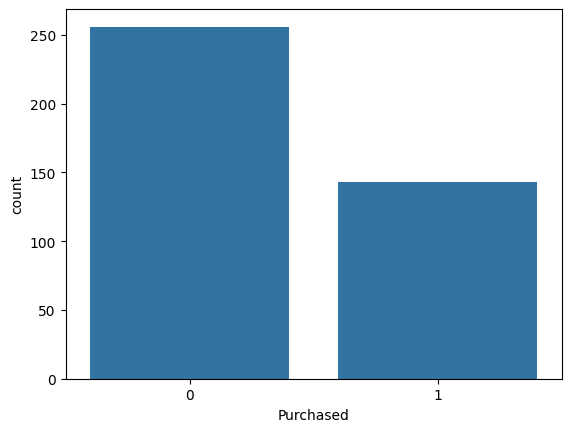

In [ ]:
import seaborn as sns
sns.countplot(data = data,x='Purchased')

train test split

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,MinMaxScaler

In [ ]:
data.columns

Index(['Country', 'Gender', 'Age', 'EstimatedSalary', 'Purchased',
       'Country_France', 'Country_Germany', 'Country_Italy', 'Gender_Female',
       'Gender_Male'],
      dtype='object')

In [ ]:
train_df,test_df = train_test_split(data,test_size=0.2)

features = ['Age', 'EstimatedSalary',
       'Country_France', 'Country_Germany', 'Country_Italy', 'Gender_Female',
       'Gender_Male']

x_train = train_df[features]
y_train = train_df['Purchased']


x_test = test_df[features]
y_test = test_df['Purchased']


In [ ]:
x_train

,Age,EstimatedSalary,Country_France,Country_Germany,Country_Italy,Gender_Female,Gender_Male
133,28,55000.0,1.0,0.0,0.0,1.0,0.0
131,30,87000.0,1.0,0.0,0.0,0.0,1.0
245,35,50000.0,0.0,0.0,1.0,1.0,0.0
180,32,117000.0,1.0,0.0,0.0,1.0,0.0
139,19,85000.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...
393,39,59000.0,0.0,1.0,0.0,1.0,0.0
81,20,49000.0,0.0,1.0,0.0,0.0,1.0
168,21,88000.0,0.0,0.0,1.0,0.0,1.0
388,48,35000.0,0.0,1.0,0.0,1.0,0.0


In [ ]:
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train.values)

In [ ]:
y_train.value_counts()

,count
Purchased,
0,206
1,113


In [ ]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(sampling_strategy='minority')

x_train, y_train = smote.fit_resample(x_train,y_train)


In [ ]:
x_train.shape

(412, 7)

In [ ]:
y_train.value_counts()

,count
Purchased,
0,206
1,206


## SVM Classifier

In [ ]:
from sklearn.svm import SVC

In [ ]:
model = SVC(C=15,kernel='poly',degree=2)

In [ ]:
model.fit(x_train,y_train)

SVC(C=15, degree=2, kernel='poly')

In [ ]:
from sklearn.metrics import classification_report

In [ ]:
y_pred = model.predict(x_train)
print(classification_report(y_train,y_pred))

              precision    recall  f1-score   support

           0       0.93      0.93      0.93       206
           1       0.93      0.93      0.93       206

    accuracy                           0.93       412
   macro avg       0.93      0.93      0.93       412
weighted avg       0.93      0.93      0.93       412



In [ ]:
x_test=scaler.transform(x_test)

y_pred = model.predict(x_test)
print(classification_report(y_test,y_pred))


              precision    recall  f1-score   support

           0       0.92      0.90      0.91        50
           1       0.84      0.87      0.85        30

    accuracy                           0.89        80
   macro avg       0.88      0.88      0.88        80
weighted avg       0.89      0.89      0.89        80



/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(


## Decision Boundary visualization

In [ ]:
train_df,test_df = train_test_split(data,test_size=0.2)

features = ['Age', 'EstimatedSalary']

x_train = train_df[features]
y_train = train_df['Purchased']


x_test = test_df[features]
y_test = test_df['Purchased']


scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train.values)


from imblearn.over_sampling import SMOTE
smote = SMOTE(sampling_strategy='minority')

x_train, y_train = smote.fit_resample(x_train,y_train)

model = SVC(C=15,kernel='poly',degree=2)

model.fit(x_train,y_train)

SVC(C=15, degree=2, kernel='poly')

In [ ]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

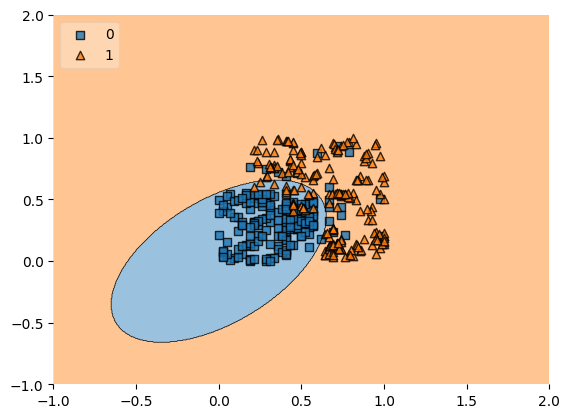

In [ ]:
plot_decision_regions(x_train, np.array(y_train), clf=model, legend=2)